# Detección y Segmentación Semántica de Caminos y Carriles con Deep Learning

> Añadir blockquote


# Fase ETL
### Juan Pablo Arteaga Paiño | A01665795

## Imports

In [ ]:
import numpy as np
import os
import matplotlib.pyplot as plt
import json
!pip install supervisely
import supervisely as sly
import shutil

from sklearn.model_selection import train_test_split
from collections import Counter
from PIL import Image
from tqdm import tqdm

## ETL

### Montar el drive y cargar el dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/DeepLearning_ProyectoBenji

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/DeepLearning_ProyectoBenji


In [ ]:
# Directorios
SOURCE_DIR = '/content/drive/MyDrive/DeepLearning_ProyectoBenji/dataset'

IMG_DIR = os.path.join(SOURCE_DIR, 'ds', 'img')
ANN_DIR = os.path.join(SOURCE_DIR, 'ds', 'ann')

# Leer metadatos
project = sly.Project(SOURCE_DIR, sly.OpenMode.READ)

print("Proyecto:", project.name)
print("Total imágenes:", project.total_items)

# Mostrar clases
for obj_class in project.meta.obj_classes:
    print(
        obj_class.name,
        obj_class.geometry_type
    )

Proyecto: dataset
Total imágenes: 374
road <class 'supervisely.geometry.bitmap.Bitmap'>
lm_solid <class 'supervisely.geometry.bitmap.Bitmap'>
lm_dashed <class 'supervisely.geometry.bitmap.Bitmap'>


### Extracción de datos

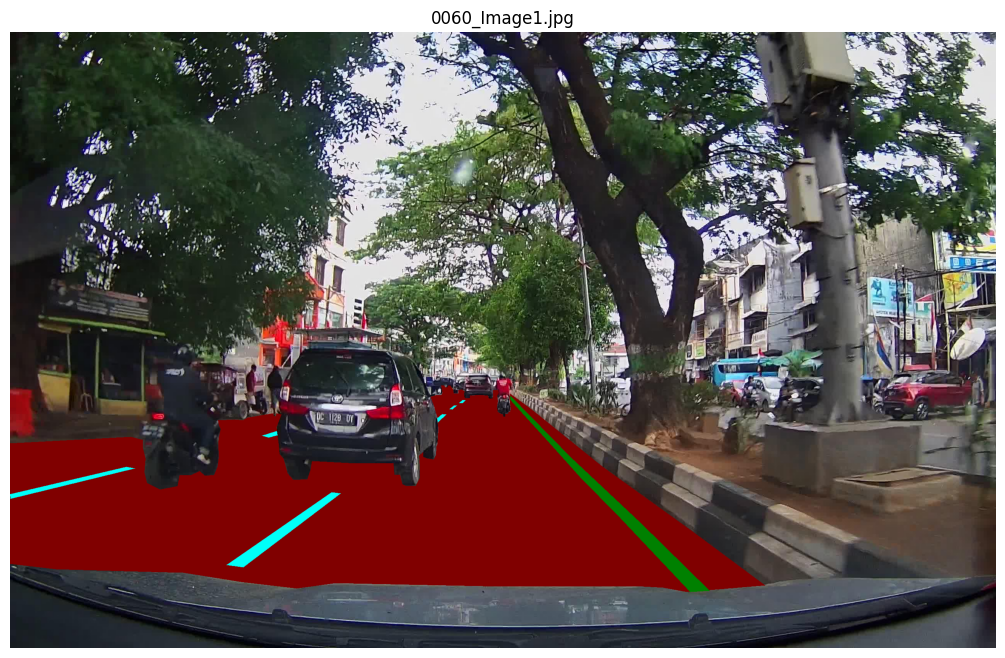

In [ ]:
# Recorrer datasets
for dataset in project.datasets:

    for item_name, image_path, ann_path in dataset.items():

        with open(ann_path, 'r') as f:
            ann_json = json.load(f)

        img = sly.image.read(image_path)
        ann = sly.Annotation.from_json(ann_json, project.meta)

        for label in ann.labels:
            label.draw(img)

        plt.figure(figsize=(14, 8))
        plt.imshow(img)
        plt.title(item_name)
        plt.axis('off')
        plt.show()

        break

    break

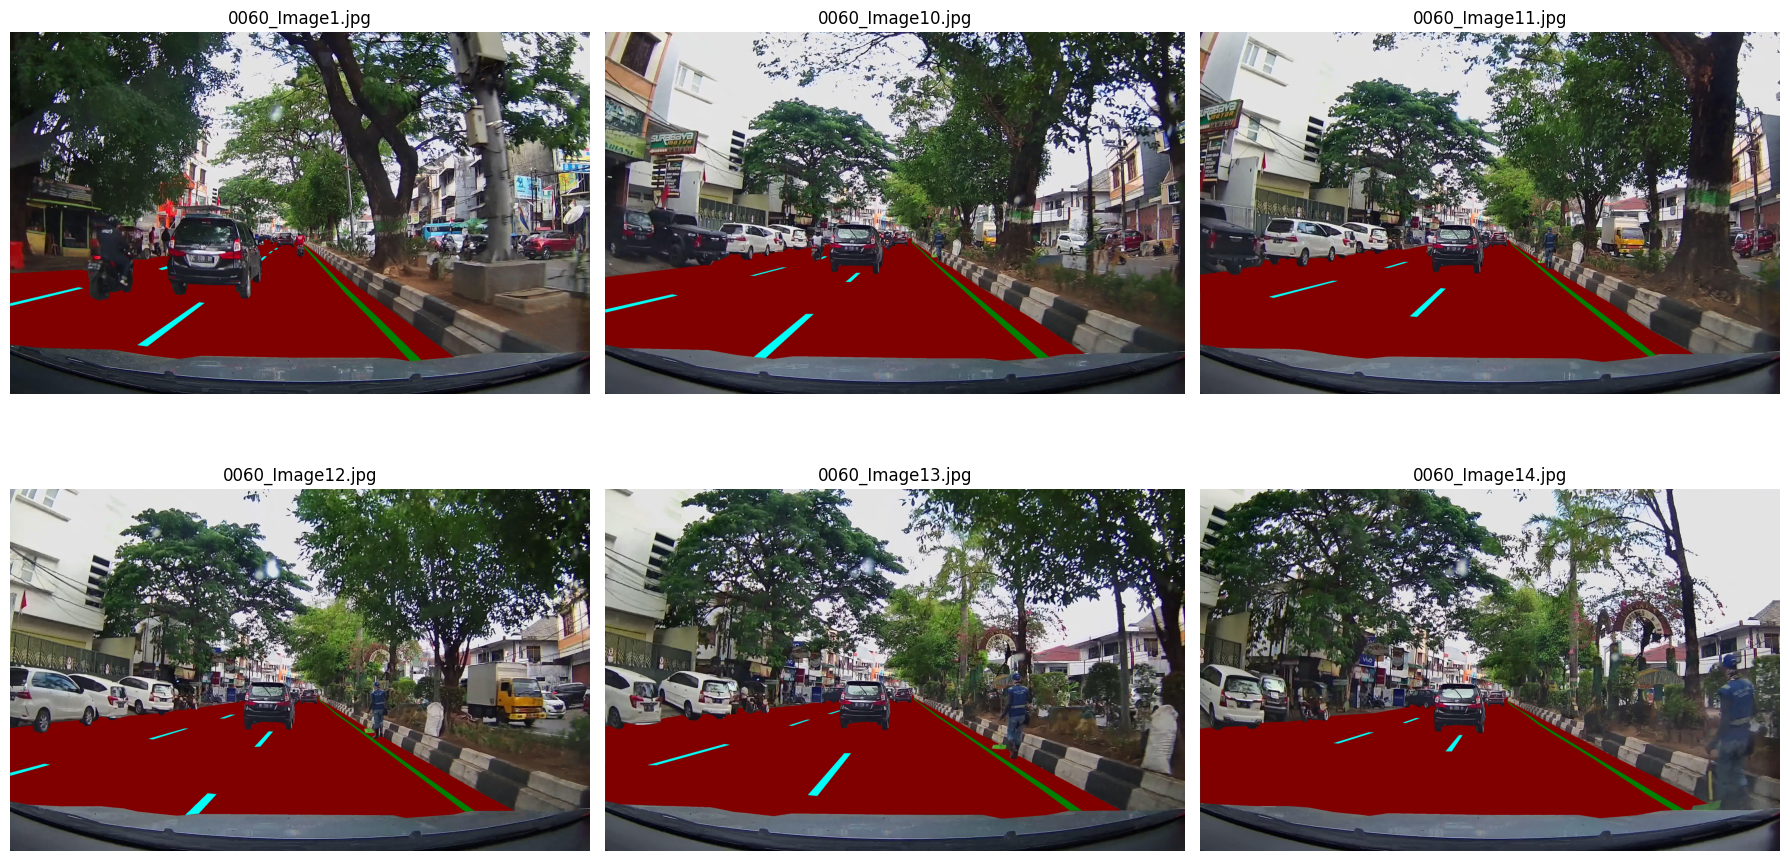

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
count = 0

for dataset in project.datasets:
    for item_name, image_path, ann_path in dataset.items():

        with open(ann_path, 'r') as f:
            ann_json = json.load(f)

        ann = sly.Annotation.from_json(ann_json, project.meta)
        img = sly.image.read(image_path)

        for label in ann.labels:
            label.draw(img)

        axes.flat[count].imshow(img)
        axes.flat[count].set_title(item_name)
        axes.flat[count].axis('off')

        count += 1

        if count == 6:
            break

    if count == 6:
        break

for i in range(count, 6):
    axes.flat[i].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
class_counter = Counter()

for dataset in project.datasets:
    for item_name, image_path, ann_path in dataset.items():

        with open(ann_path, 'r') as f:
            ann_json = json.load(f)

        ann = sly.Annotation.from_json(ann_json, project.meta)

        for label in ann.labels:
            class_counter[label.obj_class.name] += 1

print("Cantidad de objetos por clase:\n")

for class_name, count in class_counter.items():
    print(f"{class_name}: {count}")

Cantidad de objetos por clase:

lm_solid: 299
road: 374
lm_dashed: 199


### Crear máscaras

El dataset pide usar **Supervisely** para facilitar la lectura e interpretación de las anotaciones del dataset. Mediante `sly.Project` cargamos el proyecto y accedemos a sus metadatos (`project.meta`), clases y anotaciones.

A diferencia de un dataset convencional, donde las máscaras suelen estar almacenadas como imágenes independientes, este dataset utiliza anotaciones de tipo **Bitmap**. Cada objeto contiene una máscara binaria comprimida (`data`) y un origen (`origin`) que indica su posición dentro de la imagen original.

Con `sly.Annotation.from_json()` Supervisely interpreta estos datos y nos permite reconstruir una máscara semántica completa. Con el fin de evitar que el fondo sesgue las métricas y la función de pérdida, omitiremos la clase 'background' estableciendo el fondo con el valor `255` (`ignore_index` de PyTorch). Las clases de interés se remapean a partir de 0:

- `0`: Road.
- `1`: LM Solid.
- `2`: LM Dashed.
- `255`: Ignore Index (Fondo / No anotado).

In [ ]:
CLASS_MAPPING = {
    'road': 0,
    'lm_solid': 1,
    'lm_dashed': 2
}

def create_mask(ann_path, meta):
    with open(ann_path, 'r') as f:
        ann_json = json.load(f)

    ann = sly.Annotation.from_json(ann_json, meta)
    height, width = ann.img_size

    # Inicializamos la máscara con 255 (ignore_index) en lugar de 0
    mask = np.full((height, width), 255, dtype=np.uint8)

    for label in ann.labels:
        class_name = label.obj_class.name

        if class_name not in CLASS_MAPPING:
            continue

        class_id = CLASS_MAPPING[class_name]
        bitmap = label.geometry
        bitmap_data = bitmap.data

        # Coordenadas del bitmap
        x = bitmap.origin._col
        y = bitmap.origin._row

        h, w = bitmap_data.shape

        # Colocar bitmap en la máscara completa
        mask[y:y+h, x:x+w][bitmap_data > 0] = class_id

    return mask

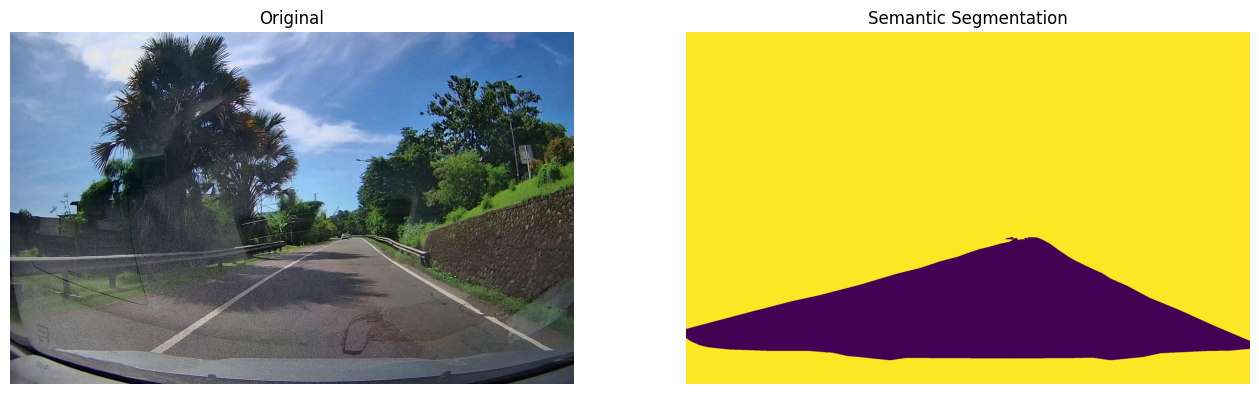

Image: (1600, 2560, 3)
Mask: (1600, 2560)
Classes in mask: [  0   1 255]


In [ ]:
image_name = os.listdir(IMG_DIR)[100]

image_path = os.path.join(IMG_DIR, image_name)
ann_path = os.path.join(ANN_DIR, image_name + '.json')

image = np.array(Image.open(image_path).convert('RGB'))

mask = create_mask(ann_path, project.meta)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(image)
axes[0].set_title('Original')

# Usamos vmin=0 y vmax=2 para las clases de interés, el valor 255 destacará en la escala
axes[1].imshow(mask, cmap='viridis', vmin=0, vmax=255)
axes[1].set_title('Semantic Segmentation')

for ax in axes:
    ax.axis('off')

plt.show()

print("Image:", image.shape)
print("Mask:", mask.shape)
print("Classes in mask:", np.unique(mask))

In [ ]:
OUTPUT_DIR = os.path.join(SOURCE_DIR, 'processed')
OUTPUT_IMG_DIR = os.path.join(OUTPUT_DIR, 'images')
OUTPUT_MASK_DIR = os.path.join(OUTPUT_DIR, 'masks')

os.makedirs(OUTPUT_IMG_DIR, exist_ok=True)
os.makedirs(OUTPUT_MASK_DIR, exist_ok=True)

image_files = [
    f for f in os.listdir(IMG_DIR)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
]

processed = 0
errors = []

for image_name in tqdm(image_files, desc="Processing dataset"):

    try:
        image_path = os.path.join(IMG_DIR, image_name)
        ann_path = os.path.join(ANN_DIR, image_name + '.json')

        if not os.path.exists(ann_path):
            errors.append((image_name, "Annotation not found"))
            continue

        image = Image.open(image_path).convert('RGB')
        mask = create_mask(ann_path, project.meta)

        if mask.shape != (image.height, image.width):
            errors.append((image_name, "Dimension mismatch"))
            continue

        image.save(os.path.join(OUTPUT_IMG_DIR, image_name))

        mask_name = os.path.splitext(image_name)[0] + '.png'

        Image.fromarray(mask).save(
            os.path.join(OUTPUT_MASK_DIR, mask_name)
        )

        processed += 1

    except Exception as e:
        errors.append((image_name, str(e)))


print("\nETL terminado")
print(f"Imágenes procesadas: {processed}")
print(f"Errores: {len(errors)}")

for name, error in errors:
    print(f"{name}: {error}")

print("Imágenes:", len(os.listdir(OUTPUT_IMG_DIR)))
print("Máscaras:", len(os.listdir(OUTPUT_MASK_DIR)))

Processing dataset: 100%|██████████| 374/374 [00:43<00:00,  8.68it/s]


ETL terminado
Imágenes procesadas: 374
Errores: 0
Imágenes: 374
Máscaras: 374


In [ ]:
mask = create_mask(ann_path, project.meta)

print("\nValores de la máscara:")

values, counts = np.unique(mask, return_counts=True)

for value, count in zip(values, counts):
    print(f"Clase {value}: {count} píxeles")

print("\nPorcentaje de píxeles por clase:")

for value, count in zip(values, counts):
    print(f"Clase {value}: {count / mask.size * 100:.2f}%")


Valores de la máscara:
Clase 0: 588515 píxeles
Clase 1: 16624 píxeles
Clase 2: 11827 píxeles
Clase 255: 3479034 píxeles

Porcentaje de píxeles por clase:
Clase 0: 14.37%
Clase 1: 0.41%
Clase 2: 0.29%
Clase 255: 84.94%


### Split

Una vez creadas las máscaras, voy a tomar un split de 70% train, 15% test, 15% validation

In [ ]:
INPUT_DIR = os.path.join(SOURCE_DIR, 'processed')
INPUT_IMG_DIR = os.path.join(SOURCE_DIR, 'processed', 'images')
INPUT_MASK_DIR = os.path.join(SOURCE_DIR, 'processed', 'masks')

OUTPUT_DIR = os.path.join(SOURCE_DIR, 'split')
OUTPUT_TRAIN_DIR = os.path.join(OUTPUT_DIR, 'train')
OUTPUT_TEST_DIR = os.path.join(OUTPUT_DIR, 'test')
OUTPUT_VAL_DIR = os.path.join(OUTPUT_DIR, 'validation')

print(f"Buscando imágenes en: {os.path.abspath(INPUT_IMG_DIR)}")
print(f"Buscando máscaras en: {os.path.abspath(INPUT_MASK_DIR)}")

todos_los_jpg = [f for f in os.listdir(INPUT_IMG_DIR) if f.lower().endswith('.jpg')] if os.path.exists(INPUT_IMG_DIR) else []
todas_las_png = [f for f in os.listdir(INPUT_MASK_DIR) if f.lower().endswith('.png')] if os.path.exists(INPUT_MASK_DIR) else []

print(f"\nArchivos .jpg encontrados: {len(todos_los_jpg)}")
print(f"Archivos .png encontrados: {len(todas_las_png)}")

# Mostrar un ejemplo de los primeros nombres si existen archivos
if todos_los_jpg: print(f"Ejemplo imagen: {todos_los_jpg[0]}")
if todas_las_png: print(f"Ejemplo máscara: {todas_las_png[0]}")

# Extraer nombres base (sin extensión)
imagenes_base = {os.path.splitext(f)[0] for f in todos_los_jpg}
mascaras_base = {os.path.splitext(f)[0] for f in todas_las_png}

nombres_base = sorted(list(imagenes_base.intersection(mascaras_base)))

print(f"\nPares alineados (intersección): {len(nombres_base)}")

# Corrección de un typo en el script anterior: os.path.splitext(f)[0] extrae el nombre base.
# Si len(nombres_base) sigue siendo 0, el script se detendrá aquí con una explicación clara.
if len(nombres_base) == 0:
    raise ValueError("No se encontraron pares coincidentes entre imágenes y máscaras. Revisa los nombres arriba.")


Buscando imágenes en: /content/drive/MyDrive/DeepLearning_ProyectoBenji/dataset/processed/images
Buscando máscaras en: /content/drive/MyDrive/DeepLearning_ProyectoBenji/dataset/processed/masks

Archivos .jpg encontrados: 374
Archivos .png encontrados: 374
Ejemplo imagen: 0060_Image1.jpg
Ejemplo máscara: 0060_Image1.png

Pares alineados (intersección): 374


In [ ]:
INPUT_IMG_DIR = os.path.join(SOURCE_DIR, 'processed', 'images')
INPUT_MASK_DIR = os.path.join(SOURCE_DIR, 'processed', 'masks')

OUTPUT_DIR = os.path.join(SOURCE_DIR, 'split')
OUTPUT_TRAIN_DIR = os.path.join(OUTPUT_DIR, 'train')
OUTPUT_TEST_DIR = os.path.join(OUTPUT_DIR, 'test')
OUTPUT_VAL_DIR = os.path.join(OUTPUT_DIR, 'validation')

imagenes_base = {os.path.splitext(f)[0] for f in os.listdir(INPUT_IMG_DIR) if f.endswith('.jpg')}
mascaras_base = {os.path.splitext(f)[0] for f in os.listdir(INPUT_MASK_DIR) if f.endswith('.png')}
nombres_base = sorted(list(imagenes_base.intersection(mascaras_base)))

train_ids, temp_ids = train_test_split(nombres_base, test_size=0.30, random_state=67)
val_ids, test_ids = train_test_split(temp_ids, test_size=0.50, random_state=67)

print(f"Total de pares (imagen/máscara) encontrados: {len(nombres_base)}")
print(f"Entrenamiento (train): {len(train_ids)}")
print(f"Validación (val):      {len(val_ids)}")
print(f"Prueba (test):        {len(test_ids)}")

splits_config = {
    OUTPUT_TRAIN_DIR: train_ids,
    OUTPUT_VAL_DIR: val_ids,
    OUTPUT_TEST_DIR: test_ids
}

for carpeta_split, lista_ids in splits_config.items():

    sub_img_dir = os.path.join(carpeta_split, 'images')
    sub_mask_dir = os.path.join(carpeta_split, 'masks')

    os.makedirs(sub_img_dir, exist_ok=True)
    os.makedirs(sub_mask_dir, exist_ok=True)

    for nombre in lista_ids:
        origen_img = os.path.join(INPUT_IMG_DIR, f"{nombre}.jpg")
        origen_mask = os.path.join(INPUT_MASK_DIR, f"{nombre}.png")

        destino_img = os.path.join(sub_img_dir, f"{nombre}.jpg")
        destino_mask = os.path.join(sub_mask_dir, f"{nombre}.png")

        shutil.copy(origen_img, destino_img)
        shutil.copy(origen_mask, destino_mask)


Total de pares (imagen/máscara) encontrados: 374
Entrenamiento (train): 261
Validación (val):      56
Prueba (test):        57


In [ ]:
def inspect_split(split_dir, split_name):

  image_dir = os.path.join(split_dir, 'images')
  mask_dir = os.path.join(split_dir, 'masks')

  images = sorted([ f for f in os.listdir(image_dir) if f.lower().endswith('.jpg') ])
  masks = sorted([ f for f in os.listdir(mask_dir) if f.lower().endswith('.png') ])

  image_names = {os.path.splitext(f)[0] for f in images}
  mask_names = {os.path.splitext(f)[0] for f in masks}

  missing_masks = image_names - mask_names
  missing_images = mask_names - image_names

  print(f"\n{'='*42}")
  print(f" {split_name.upper()}")
  print(f"{'='*42}")

  print(f"Images: {len(images)}")
  print(f"Masks: {len(masks)}")

  print(f"Images without masks: {len(missing_masks)}")
  print(f"Masks without images: {len(missing_images)}")

  assert len(missing_masks) == 0, (
      f"Existen imágenes sin máscara: {missing_masks}"
  )

  assert len(missing_images) == 0, (
      f"Existen máscaras sin imagen: {missing_images}"
  )

  print("Status: OK")

  return images

train_files = inspect_split(OUTPUT_TRAIN_DIR, "Train")
test_files = inspect_split(OUTPUT_TEST_DIR, "Test")
val_files = inspect_split(OUTPUT_VAL_DIR, "Validation")


 TRAIN
Images: 261
Masks: 261
Images without masks: 0
Masks without images: 0
Status: OK

 TEST
Images: 57
Masks: 57
Images without masks: 0
Masks without images: 0
Status: OK

 VALIDATION
Images: 56
Masks: 56
Images without masks: 0
Masks without images: 0
Status: OK


# Resumen

sigue

Split: dividir las 374 imágenes en entrenamiento, validación y test (por ejemplo, 70/15/15).

Dataset: crear una clase personalizada torch.utils.data.Dataset que cargue cada imagen y su máscara.

Transforms: redimensionar, normalizar y aplicar augmentations.

DataLoader: preparar los lotes de entrenamiento.

Model: implementar una arquitectura de segmentación como U-Net.

Training: entrenar utilizando una función de pérdida como Cross Entropy Loss.

## Resumen de la Fase ETL y Preparación de Datos

Este archivo se encarga de realizar todo el flujo de extracción, transformación, carga y particionado de datos necesario para el posterior entrenamiento del modelo de visión computacional:

### 1. Extracción de Datos
- Carga de imágenes originales desde Google Drive.
- Extracción de anotaciones en formato JSON estructurado mediante la biblioteca **Supervisely**.
- Análisis de geometrías de tipo Bitmap (máscaras binarias comprimidas con coordenadas de origen).

### 2. Transformación y Creación de Máscaras
- Reconstrucción de máscaras semánticas a partir de los datos JSON de Supervisely.
- Asignación de índices de clases específicos para las categorías de interés:
  - `0`: Road
  - `1`: LM Solid
  - `2`: LM Dashed
- Tratamiento del fondo como elemento a omitir en el entrenamiento, asignándole un valor de `255` (`ignore_index` de PyTorch).
- Almacenamiento seguro de las máscaras procesadas en formato PNG para evitar distorsiones o pérdidas de compresión que alteren las categorías.

### 3. Exploración y Validación de Clases
- Inspección visual de la correlación exacta entre imágenes originales y máscaras generadas.
- Análisis del balance de píxeles en el dataset procesado:
  - **Clase 0 (Road)**: ~14.37% de los píxeles.
  - **Clase 1 (LM Solid)**: ~0.41% de los píxeles.
  - **Clase 2 (LM Dashed)**: ~0.29% de los píxeles.
  - **Clase 255 (Fondo / Ignore Index)**: ~84.94% de los píxeles.

### 4. Particionado del Dataset (Split)
- División de las 374 imágenes en conjuntos independientes utilizando una semilla fija (`random_state=67`) para garantizar reproducibilidad:
  - **Entrenamiento (train)**: 261 imágenes/máscaras (70%)
  - **Validación (val)**: 56 imágenes/máscaras (15%)
  - **Prueba (test)**: 57 imágenes/máscaras (15%)
- Validación automatizada de consistencia (comprobación de que no existen imágenes huérfanas sin máscara ni máscaras sin su imagen correspondiente).

---

## Estado actual del cuaderno

- [x] Conexión y montaje de Google Drive.
- [x] Configuración y análisis de metadatos de Supervisely.
- [x] Definición del mapeo de clases sin la categoría activa de 'background'.
- [x] Ejecución del pipeline de conversión ETL (generación de máscaras PNG con valor 255 para el fondo).
- [x] Verificación de la integridad de los datos procesados y su balance de clases.
- [x] Creación del split reproducible de datos (train, val, test) en directorios estructurados.